In [1]:
!pip3 install pandas
!pip3 install numpy
!pip3 install scipy
!pip3 install statsmodels
!pip3 install scikit-learn
!pip3 install matplotlib
!pip3 install seaborn
!pip3 install rich
!pip3 install python-dotenv

In [2]:
import json
import logging
import os
import sys
import warnings
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path
from random import choice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from rich import print as rprint
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
%reload_ext autoreload
%autoreload 2
load_dotenv()


@dataclass
class Config:
    seed: int = int(os.getenv("SEED", "42"))
    n_boot: int = int(os.getenv("N_BOOT", "2000"))
    alpha: float = float(os.getenv("ALPHA", "0.05"))
    base_chunk: int = int(os.getenv("BASE_CHUNK", "100"))
    base_k: int = int(os.getenv("BASE_K", "5"))
    base_retriever: str = os.getenv("BASE_RETRIEVER", "hybrid")


CFG = Config()

In [4]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("analysis")
warnings.filterwarnings("ignore")

# ----------
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_LOGS = PROJECT_ROOT / "data" / "logs"
OUT_FIG = PROJECT_ROOT / "report" / "figures"
OUT_TAB = PROJECT_ROOT / "report" / "tables"
OUT_FIG.mkdir(parents=True, exist_ok=True)
OUT_TAB.mkdir(parents=True, exist_ok=True)
# ----------
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 120
RNG = np.random.default_rng(CFG.seed)
DATASETS = ["hotpotqa", "squad"]
RETRIEVERS = ["bm25", "dense", "hybrid"]
DATASET_RU = {"hotpotqa": "HotpotQA", "squad": "SQuAD"}
RETRIEVER_RU = {"bm25": "BM25", "dense": "плотный", "hybrid": "гибрид"}
METRIC_RU = {"recall_at_k": "полнота поиска", "f1": "F1 ответа", "recall": "полнота поиска"}
RESULTS = {}


def save_table(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Сохранить таблицу для отчета (csv) и вернуть ее."""
    df.to_csv(OUT_TAB / f"{name}.csv")
    return df


def save_fig(fig, name: str):
    """Сохранить рисунок для отчета (pdf + png)."""
    fig.savefig(OUT_FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUT_FIG / f"{name}.png", bbox_inches="tight", dpi=150)


def boot_ci(x: np.ndarray, n_boot: int = CFG.n_boot) -> tuple[float, float]:
    """
    Перцентильный бутстреп-интервал 95% для среднего.

    :param x: выборка
    :param n_boot: число повторов
    :return: (нижняя, верхняя) граница
    """
    x = np.asarray(x, dtype=float)
    means = RNG.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

# 1. Загрузка логов

In [5]:
answers = pd.read_parquet(DATA_LOGS / "answer_log.parquet")
search = pd.read_parquet(DATA_LOGS / "search_log.parquet")
iters = pd.read_parquet(DATA_LOGS / "iteration_log.parquet")
questions = {d: pd.read_parquet(DATA_LOGS / f"questions_{d}.parquet") for d in DATASETS}

rprint(answers.shape, search.shape, iters.shape)
rprint(answers.head(3).T)

(43200, 27)
(108000, 12)
(9600, 16)

0                         1  \
dataset                            hotpotqa                  hotpotqa   
qid                5ae60cb955429929b0807ab3  5ae60cb955429929b0807ab3   
retriever                              bm25                      bm25   
chunk_size                               50                        50   
top_k                                     1                         3   
q_type                               bridge                    bridge   
level                                  easy                      easy   
q_len                                    18                        18   
answer_len                                2                         2   
answer_is_numeric                     False                     False   
lex_overlap                             1.0                       1.0   
n_chunks_corpus                       14659                     14659   
context_words                            48                       126   
hit_at_k                                1.0                       1.0   
recall_at_k                             0.5                       1.0   
mrr_at_k                                1.0                       1.0   
answer_in_context                       1.0                       1.0   
top1_score                        24.571741                 24.571741   
score_margin                       6.521883                  6.521883   
reader_score                      14.894302                 14.894302   
pred_rank                                 1                         1   
prediction                     Flying Lotus              Flying Lotus   
gold                           Flying Lotus              Flying Lotus   
em                                      1.0                       1.0   
f1                                      1.0                       1.0   
correct                                   1                         1   
latency_ms                         0.100518                  0.100518   

                                          2  
dataset                            hotpotqa  
qid                5ae60cb955429929b0807ab3  
retriever                              bm25  
chunk_size                               50  
top_k                                     5  
q_type                               bridge  
level                                  easy  
q_len                                    18  
answer_len                                2  
answer_is_numeric                     False  
lex_overlap                             1.0  
n_chunks_corpus                       14659  
context_words                           197  
hit_at_k                                1.0  
recall_at_k                             1.0  
mrr_at_k                                1.0  
answer_in_context                       1.0  
top1_score                        24.571741  
score_margin                       6.521883  
reader_score                      14.894302  
pred_rank                                 1  
prediction                     Flying Lotus  
gold                           Flying Lotus  
em                                      1.0  
f1                                      1.0  
correct                                   1  
latency_ms                         0.100518

In [6]:
quess = answers.sample(1, random_state=CFG.seed).iloc[0]
rprint(quess[["dataset", "retriever", "chunk_size", "top_k", "gold", "prediction", "f1", "recall_at_k"]])

dataset             hotpotqa
retriever               bm25
chunk_size               200
top_k                      5
gold           New York City
prediction     New York City
f1                       1.0
recall_at_k              1.0
Name: 15158, dtype: object

# 2. Описательная статистика

In [7]:
# === 1) Выборки и корпуса ===
corpus = (
    answers.groupby(["dataset", "chunk_size"])["n_chunks_corpus"].first().unstack()
    .rename(columns=lambda c: f"chunks_{c}")
)
qstat = pd.concat(
    {
        d: questions[d][["q_len", "answer_len", "lex_overlap"]].describe().T[["mean", "std", "50%", "min", "max"]]
        for d in DATASETS
    }
)
rprint(corpus)
rprint(qstat.round(2))
save_table(corpus, "corpus")
save_table(qstat.round(3), "question_stats")
RESULTS["n_questions"] = {d: int(len(questions[d])) for d in DATASETS}
RESULTS["level_counts"] = questions["hotpotqa"]["level"].value_counts().to_dict()
RESULTS["type_counts"] = questions["hotpotqa"]["q_type"].value_counts().to_dict()

chunk_size  chunks_50  chunks_100  chunks_200
dataset                                      
hotpotqa        14659        8136        6097
squad            6859        3630        2222

mean    std    50%   min   max
hotpotqa q_len        19.18  10.11  17.00  5.00  69.0
         answer_len    2.29   1.37   2.00  1.00  11.0
         lex_overlap   0.82   0.16   0.86  0.17   1.0
squad    q_len        10.25   3.64  10.00  3.00  25.0
         answer_len    3.09   3.30   2.00  1.00  25.0
         lex_overlap   0.67   0.22   0.67  0.00   1.0

In [8]:
# === 2) Метрики по конфигурациям ===
METRICS = ["hit_at_k", "recall_at_k", "mrr_at_k", "answer_in_context", "em", "f1", "correct"]
by_cfg = answers.groupby(["dataset", "retriever", "chunk_size", "top_k"])[METRICS].mean()
save_table(by_cfg.round(4), "metrics_by_config")
rprint(by_cfg.round(3).head(24))

base = answers[(answers.chunk_size == CFG.base_chunk) & (answers.top_k == CFG.base_k)]
desc_rows = []
for d in DATASETS:
    for r in RETRIEVERS:
        part = base[(base.dataset == d) & (base.retriever == r)]
        row = {"dataset": d, "retriever": r}
        for m in ["recall_at_k", "f1", "correct"]:
            lo, hi = boot_ci(part[m].values)
            row[m] = part[m].mean()
            row[f"{m}_lo"] = lo
            row[f"{m}_hi"] = hi
        row["f1_median"] = part["f1"].median()
        row["f1_std"] = part["f1"].std()
        desc_rows.append(row)
desc_base = pd.DataFrame(desc_rows).set_index(["dataset", "retriever"])
save_table(desc_base.round(4), "desc_base")
rprint(desc_base.round(3))

hit_at_k  recall_at_k  mrr_at_k  \
dataset  retriever chunk_size top_k                                    
hotpotqa bm25      50         1         0.762        0.381     0.762   
                              3         0.925        0.630     0.835   
                              5         0.957        0.709     0.842   
                              10        0.980        0.816     0.845   
                   100        1         0.795        0.398     0.795   
                              3         0.920        0.652     0.852   
                              5         0.962        0.738     0.861   
                              10        0.993        0.857     0.866   
                   200        1         0.817        0.408     0.817   
                              3         0.923        0.656     0.865   
                              5         0.958        0.746     0.873   
                              10        0.995        0.872     0.879   
         dense     50         1         0.797        0.398     0.797   
                              3         0.955        0.753     0.870   
                              5         0.987        0.828     0.877   
                              10        0.993        0.906     0.878   
                   100        1         0.863        0.432     0.863   
                              3         0.970        0.797     0.912   
                              5         0.992        0.866     0.918   
                              10        0.998        0.924     0.918   
                   200        1         0.893        0.447     0.893   
                              3         0.977        0.807     0.932   
                              5         0.995        0.876     0.936   
                              10        0.998        0.926     0.937   

                                     answer_in_context     em     f1  correct  
dataset  retriever chunk_size top_k                                            
hotpotqa bm25      50         1                  0.382  0.283  0.340    0.347  
                              3                  0.575  0.347  0.426    0.445  
                              5                  0.652  0.367  0.449    0.472  
                              10                 0.753  0.367  0.453    0.475  
                   100        1                  0.420  0.292  0.360    0.373  
                              3                  0.628  0.368  0.447    0.467  
                              5                  0.707  0.373  0.455    0.475  
                              10                 0.818  0.397  0.477    0.498  
                   200        1                  0.445  0.302  0.375    0.388  
                              3                  0.637  0.377  0.450    0.468  
                              5                  0.725  0.375  0.455    0.473  
                              10                 0.833  0.403  0.485    0.507  
         dense     50         1                  0.402  0.283  0.352    0.363  
                              3                  0.715  0.408  0.490    0.503  
                              5                  0.780  0.410  0.493    0.513  
                              10                 0.862  0.413  0.501    0.525  
                   100        1                  0.455  0.303  0.379    0.392  
                              3                  0.768  0.418  0.509    0.528  
                              5                  0.833  0.428  0.513    0.537  
                              10                 0.890  0.422  0.510    0.537  
                   200        1                  0.482  0.312  0.396    0.410  
                              3                  0.785  0.427  0.510    0.527  
                              5                  0.842  0.430  0.512    0.533  
                              10                 0.893  0.428  0.514    0.538

recall_at_k  recall_at_k_lo  recall_at_k_hi     f1  f1_lo  \
dataset  retriever                                                              
hotpotqa bm25             0.738           0.713           0.759  0.455  0.418   
         dense            0.866           0.848           0.886  0.513  0.475   
         hybrid           0.840           0.821           0.860  0.503  0.465   
squad    bm25             0.905           0.882           0.927  0.791  0.762   
         dense            0.938           0.918           0.957  0.803  0.773   
         hybrid           0.953           0.935           0.970  0.817  0.788   

                    f1_hi  correct  correct_lo  correct_hi  f1_median  f1_std  
dataset  retriever                                                             
hotpotqa bm25       0.490    0.475       0.435       0.515      0.333   0.465  
         dense      0.550    0.537       0.498       0.577      0.667   0.466  
         hybrid     0.539    0.527       0.485       0.565      0.571   0.464  
squad    bm25       0.821    0.805       0.773       0.837      1.000   0.379  
         dense      0.831    0.815       0.785       0.843      1.000   0.372  
         hybrid     0.846    0.830       0.800       0.862      1.000   0.360

{
    'hotpotqa': {
        'share_f1_zero': 0.42333333333333334,
        'share_f1_one': 0.4116666666666667,
        'shapiro_p': 2.1195349673701955e-30
    },
    'squad': {'share_f1_zero': 0.14, 'share_f1_one': 0.7566666666666667, 'shapiro_p': 5.242745441538275e-37}
}

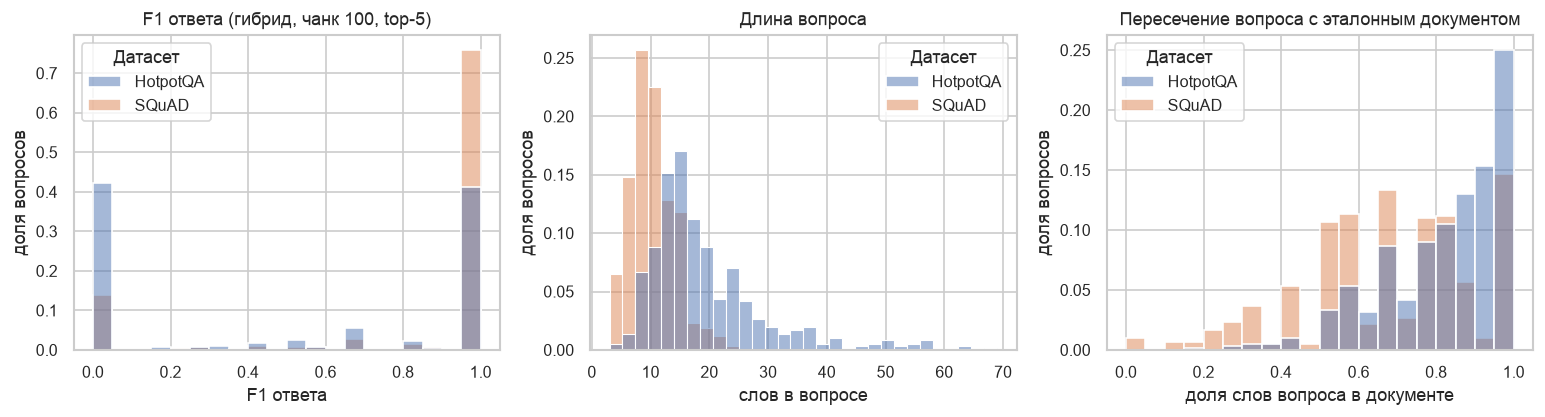

In [9]:
# === 3) Распределения ===
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
plot_base = base[base.retriever == CFG.base_retriever].assign(Датасет=lambda x: x.dataset.map(DATASET_RU))
plot_q = pd.concat([questions[d].assign(Датасет=DATASET_RU[d]) for d in DATASETS])
sns.histplot(data=plot_base, x="f1", hue="Датасет", bins=20, ax=axes[0], stat="probability", common_norm=False)
axes[0].set_title("F1 ответа (гибрид, чанк 100, top-5)")
axes[0].set_xlabel("F1 ответа")
sns.histplot(data=plot_q, x="q_len", hue="Датасет", bins=30, ax=axes[1], stat="probability", common_norm=False)
axes[1].set_title("Длина вопроса")
axes[1].set_xlabel("слов в вопросе")
sns.histplot(data=plot_q, x="lex_overlap", hue="Датасет", bins=20, ax=axes[2], stat="probability", common_norm=False)
axes[2].set_title("Пересечение вопроса с эталонным документом")
axes[2].set_xlabel("доля слов вопроса в документе")
for ax in axes:
    ax.set_ylabel("доля вопросов")
fig.tight_layout()
save_fig(fig, "distributions")

f1_shape = {
    d: {
        "share_f1_zero": float((base[(base.dataset == d) & (base.retriever == CFG.base_retriever)].f1 == 0).mean()),
        "share_f1_one": float((base[(base.dataset == d) & (base.retriever == CFG.base_retriever)].f1 == 1).mean()),
        "shapiro_p": float(stats.shapiro(base[(base.dataset == d) & (base.retriever == CFG.base_retriever)].f1.values).pvalue),
    }
    for d in DATASETS
}
RESULTS["f1_shape"] = f1_shape
rprint(f1_shape)

2026-11-21 10:42:00,815 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:00,818 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:00,900 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:00,902 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:00,983 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:00,986 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:01,067 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-21 10:42:01,069 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


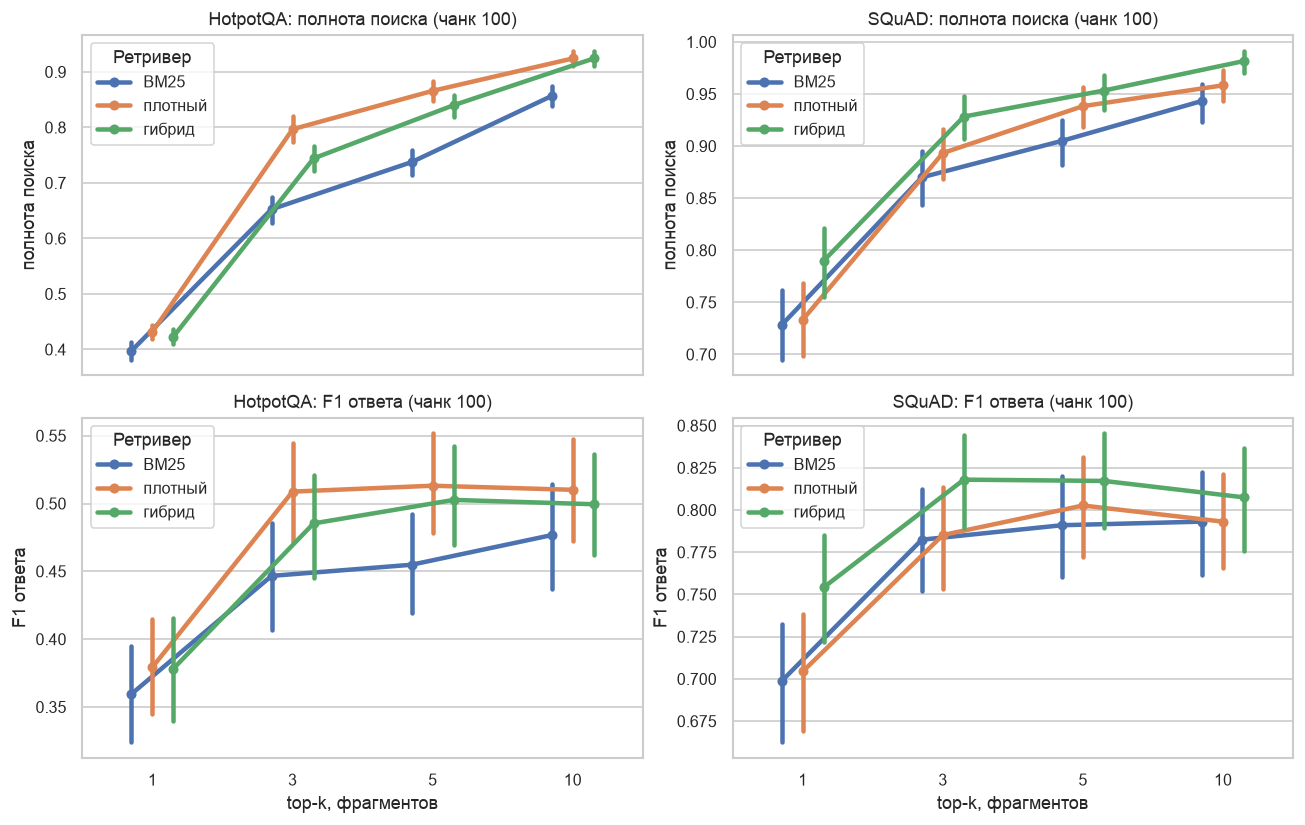

In [10]:
# === 4) Кривые по top-k ===
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for i, d in enumerate(DATASETS):
    part = answers[(answers.dataset == d) & (answers.chunk_size == CFG.base_chunk)]
    for j, m in enumerate(["recall_at_k", "f1"]):
        sns.pointplot(data=part.assign(Ретривер=part.retriever.map(RETRIEVER_RU)), x="top_k", y=m, hue="Ретривер",
                      hue_order=[RETRIEVER_RU[r] for r in RETRIEVERS], ax=axes[j, i], errorbar=("ci", 95), dodge=0.3, markersize=4)
        axes[j, i].set_title(f"{DATASET_RU[d]}: {METRIC_RU[m]} (чанк {CFG.base_chunk})")
        axes[j, i].set_xlabel("top-k, фрагментов")
        axes[j, i].set_ylabel(METRIC_RU[m])
fig.tight_layout()
save_fig(fig, "topk_curves")

# 3. Проверка гипотез

In [11]:
# === H1) Ретривер влияет на качество (парные данные: один вопрос — три ретривера) ===
def paired_matrix(df: pd.DataFrame, factor: str, levels: list, metric: str) -> pd.DataFrame:
    """Матрица вопрос × уровень фактора для парных тестов."""
    return df.pivot_table(index="qid", columns=factor, values=metric).reindex(columns=levels).dropna()


def wilcoxon_p(a: pd.Series, b: pd.Series) -> float:
    """
    Знаково-ранговый тест Вилкоксона, нулевые разности отбрасываются (zero_method='wilcox').

    :return: p-значение (1.0, если все разности нулевые)
    """
    diff = (b - a).values
    if not (diff != 0).any():
        return 1.0
    return float(stats.wilcoxon(a, b, zero_method="wilcox").pvalue)


def paired_boot_ci(diff: np.ndarray, level: float = 0.95, n_boot: int = CFG.n_boot) -> tuple[float, float]:
    """
    Бутстреп-интервал средней парной разности (вопросы ресэмплируются целиком).

    :param diff: разности по вопросам
    :param level: уровень доверия
    :return: (нижняя, верхняя) граница
    """
    diff = np.asarray(diff, dtype=float)
    means = RNG.choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
    tail = (1 - level) / 2 * 100
    return float(np.percentile(means, tail)), float(np.percentile(means, 100 - tail))


def kendall_w(friedman_stat: float, n: int, k: int) -> float:
    """Коэффициент согласованности Кендалла W из статистики Фридмана."""
    return friedman_stat / (n * (k - 1))


def friedman_block(df, factor, levels, metric_cont, metric_bin):
    """
    Фридман по непрерывной метрике + Q Кохрена по бинарной + попарные Вилкоксон/Мак-Немар (Холм).

    :return: словарь со статистиками
    """
    mat = paired_matrix(df, factor, levels, metric_cont)
    fr = stats.friedmanchisquare(*[mat[c].values for c in levels])
    binm = paired_matrix(df, factor, levels, metric_bin)
    q = cochrans_q(binm.values.astype(int))
    pairs = []
    for a, b in combinations(levels, 2):
        diff = mat[b] - mat[a]
        p = wilcoxon_p(mat[a], mat[b])
        lo, hi = paired_boot_ci(diff.values)
        tab = pd.crosstab(binm[a].astype(int), binm[b].astype(int)).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        mc = mcnemar(tab.values, exact=False, correction=True)
        pairs.append({"a": a, "b": b, "mean_a": mat[a].mean(), "mean_b": mat[b].mean(),
                      "diff_b_minus_a": diff.mean(), "diff_lo": lo, "diff_hi": hi,
                      "wilcoxon_p": p, "mcnemar_p": mc.pvalue,
                      "acc_a": binm[a].mean(), "acc_b": binm[b].mean()})
    pairs = pd.DataFrame(pairs)
    pairs["wilcoxon_p_holm"] = multipletests(pairs["wilcoxon_p"], method="holm")[1]
    pairs["mcnemar_p_holm"] = multipletests(pairs["mcnemar_p"], method="holm")[1]
    return {
        "n": len(mat), "friedman_chi2": fr.statistic, "friedman_p": fr.pvalue,
        "kendall_w": kendall_w(fr.statistic, len(mat), len(levels)),
        "cochran_q": q.statistic, "cochran_p": q.pvalue, "pairs": pairs,
    }


h1 = {}
for d in DATASETS:
    part = base[base.dataset == d]
    for metric in ["recall_at_k", "f1"]:
        res = friedman_block(part, "retriever", RETRIEVERS, metric, "correct" if metric == "f1" else "hit_at_k")
        h1[(d, metric)] = res
        rprint(d, metric, {k: v for k, v in res.items() if k != "pairs"})
        rprint(res["pairs"].round(4))

h1_table = pd.DataFrame(
    [{"dataset": d, "metric": m, **{k: v for k, v in r.items() if k != "pairs"}} for (d, m), r in h1.items()]
).set_index(["dataset", "metric"])
h1_pairs = pd.concat({f"{d}|{m}": r["pairs"] for (d, m), r in h1.items()})
save_table(h1_table, "h1_retriever")
save_table(h1_pairs, "h1_retriever_pairs")

hotpotqa recall_at_k
{
    'n': 600,
    'friedman_chi2': np.float64(170.89610389610525),
    'friedman_p': np.float64(7.769311774305431e-38),
    'kendall_w': np.float64(0.14241341991342105),
    'cochran_q': np.float64(24.333333333333332),
    'cochran_p': np.float64(5.200963470939487e-06)
}

a       b  mean_a  mean_b  diff_b_minus_a  diff_lo  diff_hi  \
0   bm25   dense  0.7375  0.8658          0.1283   0.1067   0.1517   
1   bm25  hybrid  0.7375  0.8400          0.1025   0.0842   0.1208   
2  dense  hybrid  0.8658  0.8400         -0.0258  -0.0408  -0.0117   

   wilcoxon_p  mcnemar_p   acc_a   acc_b  wilcoxon_p_holm  mcnemar_p_holm  
0       0.000     0.0003  0.9617  0.9917            0.000          0.0009  
1       0.000     0.0004  0.9617  0.9883            0.000          0.0009  
2       0.001     0.7237  0.9917  0.9883            0.001          0.7237

hotpotqa f1
{
    'n': 600,
    'friedman_chi2': np.float64(31.71428571429111),
    'friedman_p': np.float64(1.298166382501922e-07),
    'kendall_w': np.float64(0.026428571428575923),
    'cochran_q': np.float64(32.861111111111114),
    'cochran_p': np.float64(7.316449639580476e-08)
}

a       b  mean_a  mean_b  diff_b_minus_a  diff_lo  diff_hi  \
0   bm25   dense  0.4549  0.5131          0.0583   0.0350   0.0820   
1   bm25  hybrid  0.4549  0.5027          0.0478   0.0286   0.0697   
2  dense  hybrid  0.5131  0.5027         -0.0105  -0.0280   0.0060   

   wilcoxon_p  mcnemar_p   acc_a   acc_b  wilcoxon_p_holm  mcnemar_p_holm  
0      0.0000     0.0000  0.4750  0.5367           0.0000          0.0000  
1      0.0000     0.0000  0.4750  0.5267           0.0000          0.0001  
2      0.2117     0.3768  0.5367  0.5267           0.2117          0.3768

squad recall_at_k
{
    'n': 600,
    'friedman_chi2': np.float64(20.03030303030479),
    'friedman_p': np.float64(4.471723701387425e-05),
    'kendall_w': np.float64(0.01669191919192066),
    'cochran_q': np.float64(20.03030303030303),
    'cochran_p': np.float64(4.471723701391357e-05)
}

a       b  mean_a  mean_b  diff_b_minus_a  diff_lo  diff_hi  \
0   bm25   dense  0.9050  0.9383          0.0333   0.0083   0.0583   
1   bm25  hybrid  0.9050  0.9533          0.0483   0.0283   0.0700   
2  dense  hybrid  0.9383  0.9533          0.0150  -0.0033   0.0333   

   wilcoxon_p  mcnemar_p   acc_a   acc_b  wilcoxon_p_holm  mcnemar_p_holm  
0      0.0086     0.0126  0.9050  0.9383           0.0173          0.0252  
1      0.0000     0.0000  0.9050  0.9533           0.0000          0.0001  
2      0.1060     0.1508  0.9383  0.9533           0.1060          0.1508

squad f1
{
    'n': 600,
    'friedman_chi2': np.float64(6.0365296803691475),
    'friedman_p': np.float64(0.04888596978242408),
    'kendall_w': np.float64(0.005030441400307623),
    'cochran_q': np.float64(5.896551724137931),
    'cochran_p': np.float64(0.052430024659341136)
}

a       b  mean_a  mean_b  diff_b_minus_a  diff_lo  diff_hi  \
0   bm25   dense  0.7910  0.8027          0.0117  -0.0111   0.0348   
1   bm25  hybrid  0.7910  0.8172          0.0262   0.0066   0.0455   
2  dense  hybrid  0.8027  0.8172          0.0145  -0.0017   0.0301   

   wilcoxon_p  mcnemar_p  acc_a  acc_b  wilcoxon_p_holm  mcnemar_p_holm  
0      0.2595     0.4881  0.805  0.815           0.2595          0.4881  
1      0.0105     0.0214  0.805  0.830           0.0314          0.0641  
2      0.1259     0.1237  0.815  0.830           0.2517          0.2473

a       b    mean_a    mean_b  diff_b_minus_a  \
hotpotqa|recall_at_k 0   bm25   dense  0.737500  0.865833        0.128333   
                     1   bm25  hybrid  0.737500  0.840000        0.102500   
                     2  dense  hybrid  0.865833  0.840000       -0.025833   
hotpotqa|f1          0   bm25   dense  0.454865  0.513121        0.058256   
                     1   bm25  hybrid  0.454865  0.502662        0.047797   
                     2  dense  hybrid  0.513121  0.502662       -0.010459   
squad|recall_at_k    0   bm25   dense  0.905000  0.938333        0.033333   
                     1   bm25  hybrid  0.905000  0.953333        0.048333   
                     2  dense  hybrid  0.938333  0.953333        0.015000   
squad|f1             0   bm25   dense  0.791015  0.802697        0.011682   
                     1   bm25  hybrid  0.791015  0.817239        0.026224   
                     2  dense  hybrid  0.802697  0.817239        0.014542   

                         diff_lo   diff_hi    wilcoxon_p  mcnemar_p     acc_a  \
hotpotqa|recall_at_k 0  0.106667  0.151667  8.948854e-25   0.000290  0.961667   
                     1  0.084167  0.120833  3.169242e-23   0.000407  0.961667   
                     2 -0.040833 -0.011667  1.016234e-03   0.723674  0.991667   
hotpotqa|f1          0  0.035037  0.081953  2.822734e-06   0.000004  0.475000   
                     1  0.028572  0.069655  2.227303e-05   0.000027  0.475000   
                     2 -0.027991  0.005956  2.116650e-01   0.376759  0.536667   
squad|recall_at_k    0  0.008333  0.058333  8.636217e-03   0.012602  0.905000   
                     1  0.028333  0.070000  9.758408e-06   0.000020  0.905000   
                     2 -0.003333  0.033333  1.059975e-01   0.150763  0.938333   
squad|f1             0 -0.011117  0.034761  2.595084e-01   0.488074  0.805000   
                     1  0.006576  0.045475  1.045787e-02   0.021359  0.805000   
                     2 -0.001709  0.030083  1.258747e-01   0.123658  0.815000   

                           acc_b  wilcoxon_p_holm  mcnemar_p_holm  
hotpotqa|recall_at_k 0  0.991667     2.684656e-24        0.000869  
                     1  0.988333     6.338484e-23        0.000869  
                     2  0.988333     1.016234e-03        0.723674  
hotpotqa|f1          0  0.536667     8.468202e-06        0.000012  
                     1  0.526667     4.454605e-05        0.000053  
                     2  0.526667     2.116650e-01        0.376759  
squad|recall_at_k    0  0.938333     1.727243e-02        0.025204  
                     1  0.953333     2.927522e-05        0.000059  
                     2  0.953333     1.059975e-01        0.150763  
squad|f1             0  0.815000     2.595084e-01        0.488074  
                     1  0.830000     3.137360e-02        0.064076  
                     2  0.830000     2.517494e-01        0.247315

In [12]:
# === H2) Рост top-k: recall монотонно растет, F1 насыщается (тест тренда Пейджа) ===
h2_rows = []
for d in DATASETS:
    part = answers[(answers.dataset == d) & (answers.chunk_size == CFG.base_chunk) & (answers.retriever == CFG.base_retriever)]
    for metric in ["recall_at_k", "f1"]:
        mat = paired_matrix(part, "top_k", [1, 3, 5, 10], metric)
        page = stats.page_trend_test(mat.values, ranked=False)
        fr = stats.friedmanchisquare(*[mat[c].values for c in mat.columns])
        diff = (mat[10] - mat[5]).values
        lo95, hi95 = paired_boot_ci(diff, 0.95)
        lo90, hi90 = paired_boot_ci(diff, 0.90)
        if metric == "recall_at_k" and d == "squad":
            tab = pd.crosstab(mat[5].astype(int), mat[10].astype(int)).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
            p_5_10 = mcnemar(tab.values, exact=False, correction=True).pvalue
        else:
            p_5_10 = wilcoxon_p(mat[5], mat[10])
        h2_rows.append({"dataset": d, "metric": metric, "mean_k1": mat[1].mean(), "mean_k3": mat[3].mean(),
                        "mean_k5": mat[5].mean(), "mean_k10": mat[10].mean(),
                        "page_L": page.statistic, "page_p": page.pvalue, "friedman_p": fr.pvalue,
                        "p_5_vs_10": p_5_10, "diff_10_minus_5": diff.mean(), "diff_ci95_lo": lo95, "diff_ci95_hi": hi95,
                        "tost_ci90_lo": lo90, "tost_ci90_hi": hi90,
                        "equivalent_within_0_02": bool(lo90 > -0.02 and hi90 < 0.02)})
h2 = save_table(pd.DataFrame(h2_rows).set_index(["dataset", "metric"]), "h2_topk")
rprint(h2.round(4))

mean_k1  mean_k3  mean_k5  mean_k10   page_L  page_p  \
dataset  metric                                                              
hotpotqa recall_at_k   0.4233   0.7442   0.8400    0.9242  16746.0  0.0000   
         f1            0.3783   0.4853   0.5027    0.4995  15250.5  0.0002   
squad    recall_at_k   0.7900   0.9283   0.9533    0.9817  15360.0  0.0000   
         f1            0.7542   0.8180   0.8172    0.8075  15127.0  0.0362   

                      friedman_p  p_5_vs_10  diff_10_minus_5  diff_ci95_lo  \
dataset  metric                                                              
hotpotqa recall_at_k         0.0     0.0000           0.0842        0.0692   
         f1                  0.0     0.8832          -0.0032       -0.0238   
squad    recall_at_k         0.0     0.0001           0.0283        0.0167   
         f1                  0.0     0.2085          -0.0097       -0.0245   

                      diff_ci95_hi  tost_ci90_lo  tost_ci90_hi  \
dataset  metric                                                  
hotpotqa recall_at_k        0.0992        0.0717        0.0967   
         f1                 0.0179       -0.0210        0.0147   
squad    recall_at_k        0.0417        0.0167        0.0400   
         f1                 0.0037       -0.0219        0.0026   

                      equivalent_within_0_02  
dataset  metric                               
hotpotqa recall_at_k                   False  
         f1                            False  
squad    recall_at_k                   False  
         f1                            False

In [13]:
# === H3) Размер чанка влияет на качество ===
h3_rows = []
for d in DATASETS:
    part = answers[(answers.dataset == d) & (answers.top_k == CFG.base_k) & (answers.retriever == CFG.base_retriever)]
    res = friedman_block(part, "chunk_size", [50, 100, 200], "f1", "correct")
    rec = friedman_block(part, "chunk_size", [50, 100, 200], "recall_at_k", "hit_at_k")
    h3_rows.append({"dataset": d, "f1_50": res["pairs"].iloc[0]["mean_a"], "f1_100": res["pairs"].iloc[0]["mean_b"],
                    "f1_200": res["pairs"].iloc[1]["mean_b"], "friedman_f1_p": res["friedman_p"], "kendall_w_f1": res["kendall_w"],
                    "cochran_correct_p": res["cochran_p"],
                    "recall_50": rec["pairs"].iloc[0]["mean_a"], "recall_100": rec["pairs"].iloc[0]["mean_b"],
                    "recall_200": rec["pairs"].iloc[1]["mean_b"], "friedman_recall_p": rec["friedman_p"]})
h3 = save_table(pd.DataFrame(h3_rows).set_index("dataset"), "h3_chunk")
rprint(h3.round(4))

f1_50  f1_100  f1_200  friedman_f1_p  kendall_w_f1  \
dataset                                                         
hotpotqa  0.4838  0.5027  0.4978         0.6582        0.0007   
squad     0.8042  0.8172  0.8204         0.2333        0.0024   

          cochran_correct_p  recall_50  recall_100  recall_200  \
dataset                                                          
hotpotqa             0.2689     0.8017      0.8400      0.8517   
squad                0.2760     0.9317      0.9533      0.9667   

          friedman_recall_p  
dataset                      
hotpotqa             0.0000  
squad                0.0001

In [14]:
# === H4) Тип и сложность вопроса (HotpotQA, межгрупповые сравнения) ===
hp = base[(base.dataset == "hotpotqa") & (base.retriever == CFG.base_retriever)]
mw = stats.mannwhitneyu(hp[hp.q_type == "bridge"].f1, hp[hp.q_type == "comparison"].f1)
n1, n2 = (hp.q_type == "bridge").sum(), (hp.q_type == "comparison").sum()
rbc = 1 - 2 * mw.statistic / (n1 * n2)
kw = stats.kruskal(*[hp[hp.level == lv].f1 for lv in ["easy", "medium", "hard"]])
eps2 = kw.statistic / (len(hp) - 1)
ct_level = pd.crosstab(hp.level, hp.correct).reindex(["easy", "medium", "hard"])
chi_level = stats.chi2_contingency(ct_level)
cramer_v = np.sqrt(chi_level.statistic / (ct_level.values.sum() * (min(ct_level.shape) - 1)))
ct_type = pd.crosstab(hp.q_type, hp.correct)
chi_type = stats.chi2_contingency(ct_type)
level_pairs = []
for a, b in combinations(["easy", "medium", "hard"], 2):
    level_pairs.append({"a": a, "b": b, "p": stats.mannwhitneyu(hp[hp.level == a].f1, hp[hp.level == b].f1).pvalue})
level_pairs = pd.DataFrame(level_pairs)
level_pairs["p_holm"] = multipletests(level_pairs.p, method="holm")[1]
h4 = {
    "f1_bridge": hp[hp.q_type == "bridge"].f1.mean(), "f1_comparison": hp[hp.q_type == "comparison"].f1.mean(),
    "mw_p": mw.pvalue, "rank_biserial": rbc, "n_bridge": int(n1), "n_comparison": int(n2),
    "f1_easy": hp[hp.level == "easy"].f1.mean(), "f1_medium": hp[hp.level == "medium"].f1.mean(), "f1_hard": hp[hp.level == "hard"].f1.mean(),
    "recall_easy": hp[hp.level == "easy"].recall_at_k.mean(), "recall_medium": hp[hp.level == "medium"].recall_at_k.mean(), "recall_hard": hp[hp.level == "hard"].recall_at_k.mean(),
    "kruskal_H": kw.statistic, "kruskal_p": kw.pvalue, "epsilon2": eps2,
    "chi2_level": chi_level.statistic, "chi2_level_p": chi_level.pvalue, "cramer_v_level": cramer_v,
    "chi2_type_p": chi_type.pvalue,
}
type_by_level = pd.crosstab(hp.level, hp.q_type).reindex(["easy", "medium", "hard"])
save_table(type_by_level, "h4_type_by_level")
h4_ols = smf.ols("f1 ~ C(q_type, Treatment('bridge')) + C(level, Treatment('easy'))", data=hp).fit(cov_type="HC3")
h4["type_coef_adj"] = float(h4_ols.params["C(q_type, Treatment('bridge'))[T.comparison]"])
h4["type_p_adj"] = float(h4_ols.pvalues["C(q_type, Treatment('bridge'))[T.comparison]"])
h4["rank_biserial_convention"] = "1 - 2U/(n1*n2), U for bridge; negative means bridge > comparison"
RESULTS["h4"] = h4
save_table(level_pairs, "h4_level_pairs")
rprint(h4)
rprint(level_pairs)

{
    'f1_bridge': np.float64(0.5252336288050574),
    'f1_comparison': np.float64(0.3841600529100529),
    'mw_p': np.float64(0.004447042809313863),
    'rank_biserial': np.float64(-0.1691881613756614),
    'n_bridge': 504,
    'n_comparison': 96,
    'f1_easy': np.float64(0.6534646464646465),
    'f1_medium': np.float64(0.42223412698412693),
    'f1_hard': np.float64(0.4322867965367966),
    'recall_easy': np.float64(0.905),
    'recall_medium': np.float64(0.7975),
    'recall_hard': np.float64(0.8175),
    'kruskal_H': np.float64(33.57287698645276),
    'kruskal_p': np.float64(5.125572626208186e-08),
    'epsilon2': np.float64(0.056048208658518804),
    'chi2_level': np.float64(26.729363522909612),
    'chi2_level_p': np.float64(1.5696125359437847e-06),
    'cramer_v_level': np.float64(0.21106619626280604),
    'chi2_type_p': np.float64(0.024849557317574593),
    'type_coef_adj': -0.14160560110280732,
    'type_p_adj': 0.005485547725279598,
    'rank_biserial_convention': '1 - 2U/(n1*n2), U for bridge; negative means bridge > comparison'
}

a       b             p    p_holm
0    easy  medium  6.357593e-07  0.000001
1    easy    hard  4.286707e-07  0.000001
2  medium    hard  9.158272e-01  0.915827

In [15]:
# === H5) Найденный контекст не гарантирует ответа: доля ошибок ридера ===
ctx = base.groupby(["dataset", "retriever", "answer_in_context"])["correct"].agg(["mean", "size"]).unstack("answer_in_context")
save_table(ctx, "h5_context_vs_correct")
h5 = {}
for d in DATASETS:
    part = base[(base.dataset == d) & (base.retriever == CFG.base_retriever)]
    tab = pd.crosstab(part.answer_in_context, part.correct)
    odds, p = stats.fisher_exact(tab.values)
    h5[d] = {"p_correct_if_ctx": part[part.answer_in_context == 1].correct.mean(),
             "p_correct_if_no_ctx": part[part.answer_in_context == 0].correct.mean(),
             "odds_ratio": odds, "fisher_p": p, "share_ctx": part.answer_in_context.mean()}
RESULTS["h5"] = h5
rprint(h5)

{
    'hotpotqa': {
        'p_correct_if_ctx': np.float64(0.6527196652719666),
        'p_correct_if_no_ctx': np.float64(0.03278688524590164),
        'odds_ratio': np.float64(55.44578313253012),
        'fisher_p': np.float64(7.706389707679523e-40),
        'share_ctx': np.float64(0.7966666666666666)
    },
    'squad': {
        'p_correct_if_ctx': np.float64(0.8578856152512998),
        'p_correct_if_no_ctx': np.float64(0.13043478260869565),
        'odds_ratio': np.float64(40.24390243902439),
        'fisher_p': np.float64(8.738833935931276e-14),
        'share_ctx': np.float64(0.9616666666666667)
    }
}

# 4. Корреляции параметров и метрик

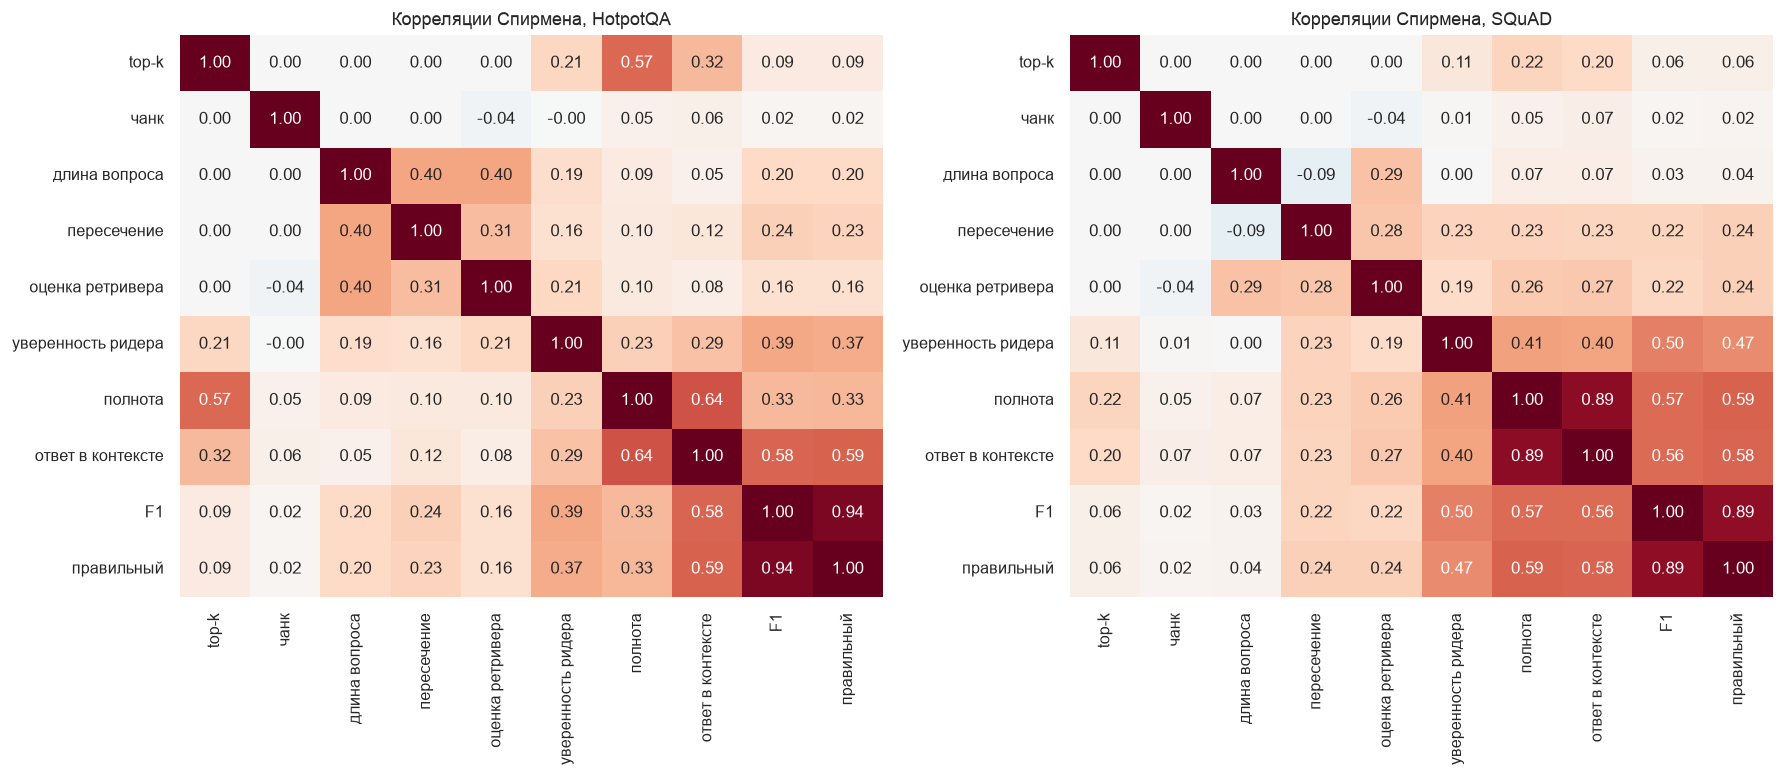

In [16]:
# === 1) Спирмен по всей сетке ===
CORR_COLS = ["top_k", "chunk_size", "context_words", "q_len", "lex_overlap", "answer_len",
             "score_margin_r", "top1_score_r", "reader_score", "recall_at_k", "mrr_at_k", "answer_in_context", "f1", "correct"]
CORR_PLOT = {"top_k": "top-k", "chunk_size": "чанк", "q_len": "длина вопроса", "lex_overlap": "пересечение",
             "top1_score_r": "оценка ретривера", "reader_score": "уверенность ридера", "recall_at_k": "полнота",
             "answer_in_context": "ответ в контексте", "f1": "F1", "correct": "правильный"}
answers["top1_score_r"] = answers.groupby(["dataset", "retriever", "chunk_size"])["top1_score"].rank(pct=True)
answers["score_margin_r"] = answers.groupby(["dataset", "retriever", "chunk_size"])["score_margin"].rank(pct=True)
corr = {}
for d in DATASETS:
    part = answers[answers.dataset == d][CORR_COLS]
    rho = part.corr(method="spearman")
    corr[d] = rho
    save_table(rho.round(3), f"spearman_{d}")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.6))
for ax, d in zip(axes, DATASETS):
    sub = corr[d].loc[list(CORR_PLOT), list(CORR_PLOT)].rename(index=CORR_PLOT, columns=CORR_PLOT)
    sns.heatmap(sub, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={"size": 10})
    ax.set_title(f"Корреляции Спирмена, {DATASET_RU[d]}")
fig.tight_layout()
save_fig(fig, "spearman")

In [17]:
# === 2) Значимость ключевых пар с поправкой Холма ===
KEY_PAIRS = [("top_k", "recall_at_k"), ("top_k", "f1"), ("chunk_size", "f1"), ("context_words", "f1"),
             ("lex_overlap", "recall_at_k"), ("lex_overlap", "f1"), ("q_len", "f1"), ("top1_score_r", "recall_at_k"),
             ("score_margin_r", "f1"), ("reader_score", "correct"), ("recall_at_k", "f1")]
rows = []
for d in DATASETS:
    part = answers[answers.dataset == d]
    per_q = part.groupby("qid")
    for a, b in KEY_PAIRS:
        r, p = stats.spearmanr(part[a], part[b])
        rows.append({"dataset": d, "x": a, "y": b, "rho": r, "p": p})
key_corr = pd.DataFrame(rows)
key_corr["p_holm"] = multipletests(key_corr.p, method="holm")[1]
save_table(key_corr.set_index(["dataset", "x", "y"]).round(4), "key_corr")
rprint(key_corr.round(4))

dataset               x            y     rho       p  p_holm
0   hotpotqa           top_k  recall_at_k  0.5749  0.0000  0.0000
1   hotpotqa           top_k           f1  0.0873  0.0000  0.0000
2   hotpotqa      chunk_size           f1  0.0219  0.0013  0.0039
3   hotpotqa   context_words           f1  0.0900  0.0000  0.0000
4   hotpotqa     lex_overlap  recall_at_k  0.0982  0.0000  0.0000
5   hotpotqa     lex_overlap           f1  0.2419  0.0000  0.0000
6   hotpotqa           q_len           f1  0.1962  0.0000  0.0000
7   hotpotqa    top1_score_r  recall_at_k  0.0985  0.0000  0.0000
8   hotpotqa  score_margin_r           f1 -0.0167  0.0140  0.0140
9   hotpotqa    reader_score      correct  0.3693  0.0000  0.0000
10  hotpotqa     recall_at_k           f1  0.3277  0.0000  0.0000
11     squad           top_k  recall_at_k  0.2195  0.0000  0.0000
12     squad           top_k           f1  0.0606  0.0000  0.0000
13     squad      chunk_size           f1  0.0213  0.0018  0.0039
14     squad   context_words           f1  0.0755  0.0000  0.0000
15     squad     lex_overlap  recall_at_k  0.2300  0.0000  0.0000
16     squad     lex_overlap           f1  0.2226  0.0000  0.0000
17     squad           q_len           f1  0.0317  0.0000  0.0000
18     squad    top1_score_r  recall_at_k  0.2647  0.0000  0.0000
19     squad  score_margin_r           f1  0.2256  0.0000  0.0000
20     squad    reader_score      correct  0.4750  0.0000  0.0000
21     squad     recall_at_k           f1  0.5664  0.0000  0.0000

In [18]:
# === 3) Точечно-бисериальная: уверенность ридера и правильность в базовой конфигурации ===
pb = {}
for d in DATASETS:
    part = base[(base.dataset == d) & (base.retriever == CFG.base_retriever)]
    r, p = stats.pointbiserialr(part.correct, part.reader_score)
    pb[d] = {"r_pb": r, "p": p}
RESULTS["point_biserial"] = pb
rprint(pb)

{
    'hotpotqa': {'r_pb': np.float64(0.3040166849945645), 'p': np.float64(2.6939076068539832e-14)},
    'squad': {'r_pb': np.float64(0.42403012532046924), 'p': np.float64(1.3948721579885627e-27)}
}

# 5. Регрессия качества ~ параметры

In [19]:
# === 1) OLS с кластерными ошибками по вопросу ===
reg = answers.copy()
reg["log2_k"] = np.log2(reg["top_k"])
reg["chunk"] = reg["chunk_size"].astype(str)
FORMULA = "f1 ~ C(retriever, Treatment('bm25')) * C(dataset) + log2_k * C(dataset) + C(chunk, Treatment('100')) + q_len + lex_overlap + answer_is_numeric"
ols = smf.ols(FORMULA, data=reg).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(reg["qid"])[0]})
rprint(ols.summary())
ols_tab = pd.DataFrame({"coef": ols.params, "se": ols.bse, "p": ols.pvalues,
                        "ci_lo": ols.conf_int()[0], "ci_hi": ols.conf_int()[1]})
save_table(ols_tab.round(4), "ols_f1")
RESULTS["ols"] = {"r2": ols.rsquared, "r2_adj": ols.rsquared_adj, "n": int(ols.nobs), "n_clusters": int(reg.qid.nunique())}

OLS Regression Results                            
==============================================================================
Dep. Variable:                     f1   R-squared:                       0.206
Model:                            OLS   Adj. R-squared:                  0.206
Method:                 Least Squares   F-statistic:                     68.05
Date:                Sat, 21 Nov 2026   Prob (F-statistic):          4.26e-126
Time:                        10:42:03   Log-Likelihood:                -22539.
No. Observations:               43200   AIC:                         4.510e+04
Df Residuals:                   43187   BIC:                         4.522e+04
Df Model:                          12                                         
Covariance Type:              cluster                                         
===================================================================================================================
==============
                                                                    coef    std err          z      P>|z|      
[0.025      0.975]
-------------------------------------------------------------------------------------------------------------------
--------------
Intercept                                                        -0.1633      0.045     -3.643      0.000      
-0.251      -0.075
C(retriever, Treatment('bm25'))[T.dense]                          0.0425      0.008      5.388      0.000       
0.027       0.058
C(retriever, Treatment('bm25'))[T.hybrid]                         0.0295      0.005      6.418      0.000       
0.021       0.039
C(dataset)[T.squad]                                               0.5072      0.023     21.742      0.000       
0.461       0.553
C(chunk, Treatment('100'))[T.200]                                 0.0117      0.004      3.097      0.002       
0.004       0.019
C(chunk, Treatment('100'))[T.50]                                 -0.0113      0.006     -2.035      0.042      
-0.022      -0.000
answer_is_numeric[T.True]                                        -0.0623      0.022     -2.793      0.005      
-0.106      -0.019
C(retriever, Treatment('bm25'))[T.dense]:C(dataset)[T.squad]     -0.0337      0.012     -2.849      0.004      
-0.057      -0.011
C(retriever, Treatment('bm25'))[T.hybrid]:C(dataset)[T.squad]     0.0030      0.007      0.406      0.685      
-0.012       0.018
log2_k                                                            0.0373      0.005      8.284      0.000       
0.029       0.046
log2_k:C(dataset)[T.squad]                                       -0.0158      0.005     -2.898      0.004      
-0.026      -0.005
q_len                                                             0.0070      0.001      5.873      0.000       
0.005       0.009
lex_overlap                                                       0.4903      0.049     10.038      0.000       
0.395       0.586
==============================================================================
Omnibus:                     7313.614   Durbin-Watson:                   0.834
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2428.955
Skew:                          -0.357   Prob(JB):                         0.00
Kurtosis:                       2.083   Cond. No.                         146.
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)

In [20]:
# === 2) Доля дисперсии: параметры системы против свойств вопроса ===
sys_only = smf.ols("f1 ~ C(retriever) * C(dataset) + log2_k * C(dataset) + C(chunk)", data=reg).fit()
q_fe = smf.ols("f1 ~ C(qid)", data=reg).fit()
RESULTS["variance_split"] = {"r2_system_params": sys_only.rsquared, "r2_question_fixed_effects": q_fe.rsquared,
                             "r2_full_model": ols.rsquared}
for d in DATASETS:
    part = reg[reg.dataset == d]
    RESULTS["variance_split"][f"{d}_r2_system_params"] = smf.ols("f1 ~ C(retriever) + log2_k + C(chunk)", data=part).fit().rsquared
    RESULTS["variance_split"][f"{d}_r2_question"] = smf.ols("f1 ~ C(qid)", data=part).fit().rsquared
rprint(RESULTS["variance_split"])

{
    'r2_system_params': np.float64(0.13765698716302488),
    'r2_question_fixed_effects': np.float64(0.6933445184888556),
    'r2_full_model': np.float64(0.20573855834078858),
    'hotpotqa_r2_system_params': np.float64(0.011418324503356003),
    'hotpotqa_r2_question': np.float64(0.6794799717220282),
    'squad_r2_system_params': np.float64(0.006527327251756865),
    'squad_r2_question': np.float64(0.6012179442358725)
}

In [21]:
# === 3) Логистическая регрессия правильности (GEE, обменная корреляция внутри вопроса) ===
gee = smf.gee(
    "correct ~ C(retriever, Treatment('bm25')) + C(dataset) + log2_k + C(chunk, Treatment('100')) + q_len + lex_overlap + answer_is_numeric",
    groups="qid", data=reg, family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable(),
).fit()
rprint(gee.summary())
gee_tab = pd.DataFrame({"coef": gee.params, "odds_ratio": np.exp(gee.params), "se": gee.bse, "p": gee.pvalues,
                        "or_lo": np.exp(gee.conf_int()[0]), "or_hi": np.exp(gee.conf_int()[1])})
save_table(gee_tab.round(4), "gee_correct")

GEE Regression Results                              
===================================================================================
Dep. Variable:                     correct   No. Observations:                43200
Model:                                 GEE   No. clusters:                     1200
Method:                        Generalized   Min. cluster size:                  36
                      Estimating Equations   Max. cluster size:                  36
Family:                           Binomial   Mean cluster size:                36.0
Dependence structure:         Exchangeable   Num. iterations:                    55
Date:                     Sat, 21 Nov 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         10:42:09
=============================================================================================================
                                                coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
Intercept                                    -3.6371      0.360    -10.114      0.000      -4.342      -2.932
C(retriever, Treatment('bm25'))[T.dense]      0.1420      0.035      4.072      0.000       0.074       0.210
C(retriever, Treatment('bm25'))[T.hybrid]     0.1790      0.022      8.200      0.000       0.136       0.222
C(dataset)[T.squad]                           2.6284      0.173     15.157      0.000       2.288       2.968
C(chunk, Treatment('100'))[T.200]             0.0606      0.023      2.649      0.008       0.016       0.105
C(chunk, Treatment('100'))[T.50]             -0.0727      0.034     -2.111      0.035      -0.140      -0.005
answer_is_numeric[T.True]                    -0.2825      0.156     -1.815      0.069      -0.588       0.023
log2_k                                        0.1678      0.017     10.084      0.000       0.135       0.200
q_len                                         0.0214      0.009      2.362      0.018       0.004       0.039
lex_overlap                                   3.2415      0.388      8.348      0.000       2.480       4.003
==============================================================================
Skew:                         -0.3841   Kurtosis:                      -0.8160
Centered skew:                -0.5042   Centered kurtosis:              2.8962
==============================================================================

,coef,odds_ratio,se,p,or_lo,or_hi
Intercept,-3.6371,0.0263,0.3596,0.0000,0.0130,0.0533
"C(retriever, Treatment('bm25'))[T.dense]",0.1420,1.1525,0.0349,0.0000,1.0764,1.2340
"C(retriever, Treatment('bm25'))[T.hybrid]",0.1790,1.1961,0.0218,0.0000,1.1460,1.2484
C(dataset)[T.squad],2.6284,13.8511,0.1734,0.0000,9.8599,19.4578
"C(chunk, Treatment('100'))[T.200]",0.0606,1.0625,0.0229,0.0081,1.0159,1.1112
"C(chunk, Treatment('100'))[T.50]",-0.0727,0.9299,0.0344,0.0347,0.8691,0.9948
answer_is_numeric[T.True],-0.2825,0.7539,0.1556,0.0695,0.5557,1.0228
log2_k,0.1678,1.1827,0.0166,0.0000,1.1448,1.2219
q_len,0.0214,1.0217,0.0091,0.0182,1.0037,1.0400
lex_overlap,3.2415,25.5719,0.3883,0.0000,11.9461,54.7391


C(retriever, Treatment('bm25'))[T.dense]     1.33
C(retriever, Treatment('bm25'))[T.hybrid]    1.33
C(dataset)[T.squad]                          1.43
C(chunk, Treatment('100'))[T.200]            1.33
C(chunk, Treatment('100'))[T.50]             1.33
answer_is_numeric[T.True]                    1.00
log2_k                                       1.00
q_len                                        1.40
lex_overlap                                  1.20
dtype: float64

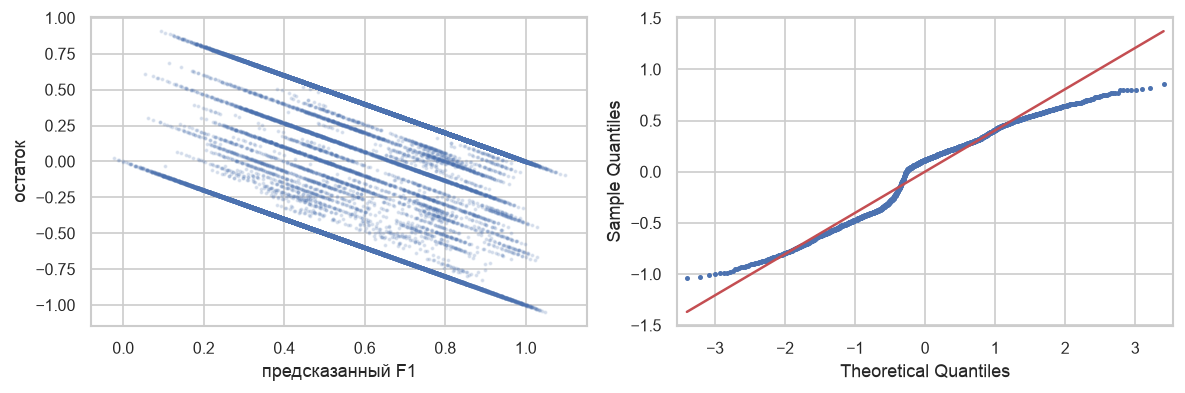

In [22]:
# === 4) Диагностика: VIF и остатки ===
main_eff = smf.ols("f1 ~ C(retriever, Treatment('bm25')) + C(dataset) + log2_k + C(chunk, Treatment('100')) + q_len + lex_overlap + answer_is_numeric", data=reg).fit()
X = pd.DataFrame(main_eff.model.exog, columns=main_eff.model.exog_names)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
save_table(vif.round(2).to_frame("vif"), "vif")
rprint(vif.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].scatter(ols.fittedvalues, ols.resid, s=2, alpha=0.15)
axes[0].set_xlabel("предсказанный F1")
axes[0].set_ylabel("остаток")
sm.qqplot(ols.resid.sample(3000, random_state=CFG.seed), line="s", ax=axes[1], markersize=2)
fig.tight_layout()
save_fig(fig, "ols_diagnostics")

# 6. Классификация правильный / неправильный

In [23]:
# === 1) Признаки и групповая кросс-валидация по вопросу ===
clf_df = answers.copy()
clf_df["is_hotpot"] = (clf_df.dataset == "hotpotqa").astype(int)
for r in RETRIEVERS:
    clf_df[f"ret_{r}"] = (clf_df.retriever == r).astype(int)
FEATURES_PRE = ["is_hotpot", "ret_bm25", "ret_dense", "ret_hybrid", "top_k", "chunk_size", "context_words",
                "q_len", "top1_score_r", "score_margin_r"]
FEATURES_PRE_NO_DS = [f for f in FEATURES_PRE if f != "is_hotpot"]
FEATURES_POST = FEATURES_PRE + ["reader_score", "pred_rank"]
y = clf_df["correct"].values
groups = clf_df["qid"].values
cv = GroupKFold(n_splits=5)


def cv_eval(model_factory, features):
    """
    Метрики на 5 групповых фолдах (вопрос целиком в одном фолде).

    :return: словарь средних метрик и out-of-fold предсказания
    """
    oof = np.zeros(len(y))
    for tr, te in cv.split(clf_df, y, groups):
        m = model_factory()
        m.fit(clf_df.iloc[tr][features].astype(float), y[tr])
        oof[te] = m.predict_proba(clf_df.iloc[te][features].astype(float))[:, 1]
    return {"roc_auc": roc_auc_score(y, oof), "pr_auc": average_precision_score(y, oof),
            "accuracy": accuracy_score(y, oof >= 0.5), "brier": brier_score_loss(y, oof)}, oof


MODELS = {
    "logreg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "gboost": lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=CFG.seed),
}
clf_rows, oofs = [], {}
majority = max(y.mean(), 1 - y.mean())
clf_rows.append({"model": "majority", "features": "-", "roc_auc": 0.5, "pr_auc": y.mean(), "accuracy": majority, "brier": y.mean() * (1 - y.mean())})
for fname, feats in [("pre_reader_no_dataset", FEATURES_PRE_NO_DS), ("pre_reader", FEATURES_PRE), ("with_reader", FEATURES_POST)]:
    for mname, factory in MODELS.items():
        res, oof = cv_eval(factory, feats)
        oofs[(mname, fname)] = oof
        clf_rows.append({"model": mname, "features": fname, **res})
clf_tab = save_table(pd.DataFrame(clf_rows).set_index(["model", "features"]), "classification")
rprint(clf_tab.round(4))

roc_auc  pr_auc  accuracy   brier
model    features                                                
majority -                       0.5000  0.6352    0.6352  0.2317
logreg   pre_reader_no_dataset   0.6373  0.7403    0.6541  0.2196
gboost   pre_reader_no_dataset   0.7107  0.7940    0.6809  0.2048
logreg   pre_reader              0.7367  0.8077    0.6951  0.1953
gboost   pre_reader              0.7468  0.8201    0.6993  0.1941
logreg   with_reader             0.8349  0.8957    0.7615  0.1595
gboost   with_reader             0.8373  0.8863    0.7662  0.1591

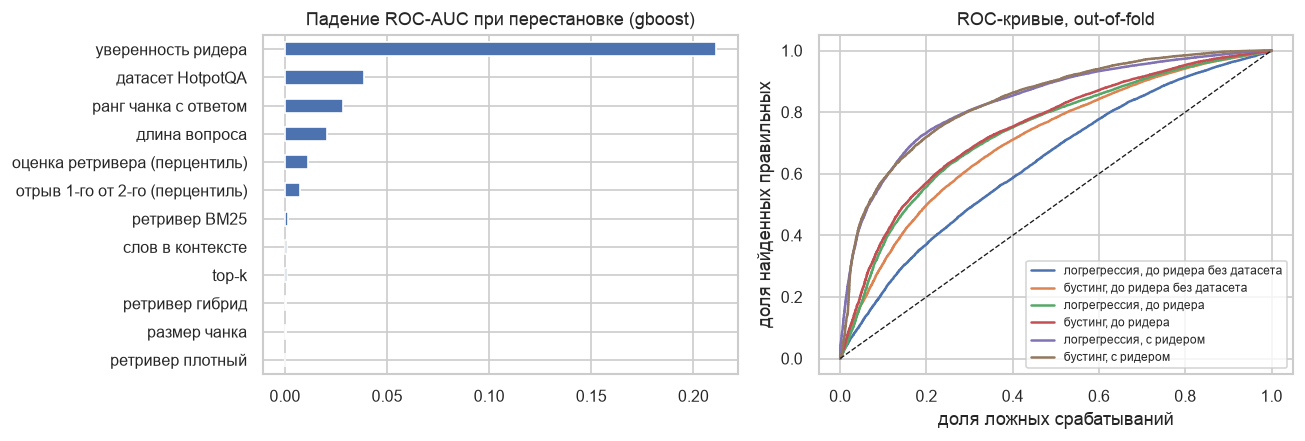

In [24]:
# === 2) Важность признаков (перестановочная, на отложенном фолде) ===
tr, te = next(cv.split(clf_df, y, groups))
gb = MODELS["gboost"]().fit(clf_df.iloc[tr][FEATURES_POST].astype(float), y[tr])
pi = permutation_importance(gb, clf_df.iloc[te][FEATURES_POST].astype(float), y[te], scoring="roc_auc", n_repeats=5, random_state=CFG.seed)
FEATURE_RU = {"is_hotpot": "датасет HotpotQA", "ret_bm25": "ретривер BM25", "ret_dense": "ретривер плотный", "ret_hybrid": "ретривер гибрид",
              "top_k": "top-k", "chunk_size": "размер чанка", "context_words": "слов в контексте", "q_len": "длина вопроса",
              "top1_score_r": "оценка ретривера (перцентиль)", "score_margin_r": "отрыв 1-го от 2-го (перцентиль)",
              "reader_score": "уверенность ридера", "pred_rank": "ранг чанка с ответом"}
imp = pd.Series(pi.importances_mean, index=FEATURES_POST).sort_values(ascending=False)
save_table(imp.round(4).to_frame("auc_drop"), "feature_importance")
lr = MODELS["logreg"]().fit(clf_df[FEATURES_PRE].astype(float), y)
lr_coef = pd.Series(lr[-1].coef_[0], index=FEATURES_PRE).sort_values()
save_table(lr_coef.round(4).to_frame("std_coef"), "logreg_coef")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
imp.rename(FEATURE_RU).plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_title("Падение ROC-AUC при перестановке (gboost)")
from sklearn.metrics import roc_curve
for (mname, fname), oof in oofs.items():
    fpr, tpr, _ = roc_curve(y, oof)
    names = {"logreg": "логрегрессия", "gboost": "бустинг", "pre_reader_no_dataset": "до ридера без датасета",
             "pre_reader": "до ридера", "with_reader": "с ридером"}
    axes[1].plot(fpr, tpr, label=f"{names[mname]}, {names[fname]}")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].legend(fontsize=7)
axes[1].set_title("ROC-кривые, out-of-fold")
axes[1].set_xlabel("доля ложных срабатываний")
axes[1].set_ylabel("доля найденных правильных")
fig.tight_layout()
save_fig(fig, "classification")

# 7. Динамика по итерациям

recall  answer_in_context     f1  correct  \
dataset  mode      iteration                                              
hotpotqa iterative 1           0.744              0.708  0.486    0.507   
                   2           0.916              0.892  0.506    0.535   
                   3           0.948              0.925  0.511    0.538   
                   4           0.954              0.928  0.503    0.528   
         single    1           0.744              0.708  0.485    0.507   
                   2           0.871              0.828  0.503    0.528   
                   3           0.913              0.878  0.499    0.527   
                   4           0.940              0.920  0.494    0.518   
squad    iterative 1           0.928              0.937  0.818    0.833   
                   2           0.957              0.963  0.812    0.825   
                   3           0.963              0.968  0.795    0.808   
                   4           0.970              0.975  0.794    0.807   
         single    1           0.928              0.937  0.818    0.833   
                   2           0.958              0.967  0.815    0.828   
                   3           0.978              0.978  0.807    0.820   
                   4           0.987              0.990  0.803    0.815   

                              context_words  
dataset  mode      iteration                 
hotpotqa iterative 1                178.982  
                   2                381.018  
                   3                587.813  
                   4                795.967  
         single    1                179.048  
                   2                379.960  
                   3                591.142  
                   4                800.278  
squad    iterative 1                225.932  
                   2                440.170  
                   3                652.335  
                   4                862.645  
         single    1                226.018  
                   2                440.712  
                   3                658.113  
                   4                870.065

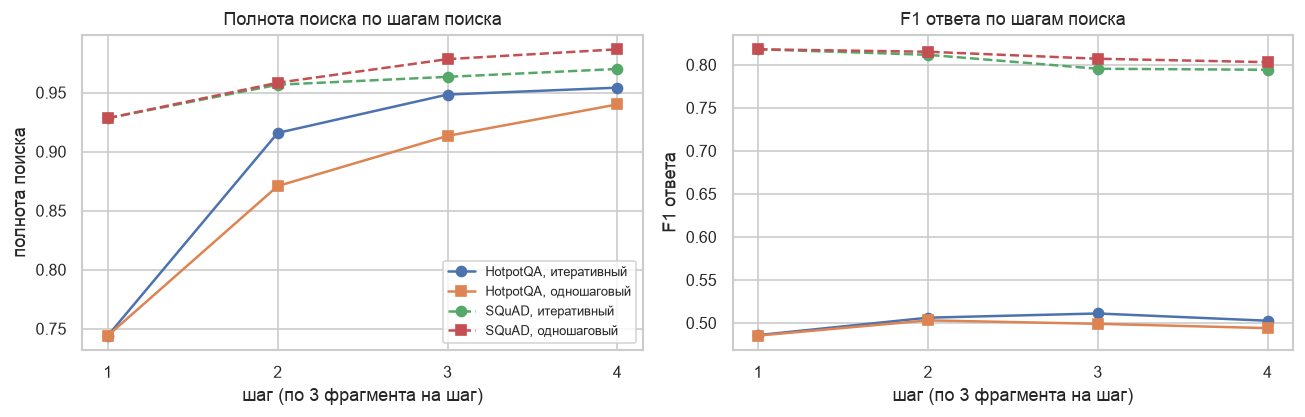

In [25]:
# === 1) Средние по итерациям ===
it_mean = iters.groupby(["dataset", "mode", "iteration"])[["recall", "answer_in_context", "f1", "correct", "context_words"]].mean()
save_table(it_mean.round(4), "iterations_mean")
rprint(it_mean.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric in zip(axes, ["recall", "f1"]):
    for (d, mode), g in iters.groupby(["dataset", "mode"]):
        m = g.groupby("iteration")[metric].mean()
        mode_ru = "итеративный" if mode == "iterative" else "одношаговый"
        ax.plot(m.index, m.values, marker="o" if mode == "iterative" else "s", linestyle="-" if d == "hotpotqa" else "--", label=f"{DATASET_RU[d]}, {mode_ru}")
    ax.set_title(f"{METRIC_RU[metric].capitalize()} по шагам поиска")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel("шаг (по 3 фрагмента на шаг)")
    ax.set_ylabel(METRIC_RU[metric])
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "iterations")

In [26]:
# === 2) Тренд внутри итеративного режима и сравнение с одношаговым поиском ===
it_rows = []
for d in DATASETS:
    part = iters[(iters.dataset == d)]
    for mode in ["iterative", "single"]:
        for metric in ["recall", "f1"]:
            mat = part[part["mode"] == mode].pivot_table(index="qid", columns="iteration", values=metric)
            page_up = stats.page_trend_test(mat.values, ranked=False)
            page_down = stats.page_trend_test(mat.values[:, ::-1], ranked=False)
            fr = stats.friedmanchisquare(*[mat[c].values for c in mat.columns])
            lo, hi = paired_boot_ci((mat[4] - mat[1]).values)
            it_rows.append({"dataset": d, "mode": mode, "metric": metric, "page_up_p": page_up.pvalue, "page_down_p": page_down.pvalue,
                            "friedman_p": fr.pvalue, "delta_1_to_4": mat[4].mean() - mat[1].mean(), "delta_lo": lo, "delta_hi": hi})
    for it in [2, 3, 4]:
        for metric in ["recall", "f1"]:
            a = part[(part["mode"] == "iterative") & (part.iteration == it)].set_index("qid")[metric]
            b = part[(part["mode"] == "single") & (part.iteration == it)].set_index("qid")[metric].reindex(a.index)
            if metric == "recall" and d == "squad":
                tab = pd.crosstab(b.astype(int), a.astype(int)).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
                p, test = mcnemar(tab.values, exact=False, correction=True).pvalue, "mcnemar"
            else:
                p, test = wilcoxon_p(b, a), "wilcoxon"
            lo, hi = paired_boot_ci((a - b).values)
            it_rows.append({"dataset": d, "mode": f"iter_vs_single_t{it}", "metric": metric, "test": test,
                            "mean_iterative": a.mean(), "mean_single": b.mean(), "p": p, "delta_lo": lo, "delta_hi": hi})
it_tests = pd.DataFrame(it_rows)
cmp_mask = it_tests["mode"].str.startswith("iter_vs_single")
it_tests.loc[cmp_mask, "p_holm"] = it_tests[cmp_mask].groupby(["dataset", "metric"])["p"].transform(lambda s: multipletests(s, method="holm")[1])
it_tests = save_table(it_tests, "iterations_tests")
rprint(it_tests.round(4))

dataset               mode  metric  page_up_p  page_down_p  friedman_p  \
0   hotpotqa          iterative  recall     0.0000       1.0000      0.0000   
1   hotpotqa          iterative      f1     0.3566       0.6434      0.1738   
2   hotpotqa             single  recall     0.0000       1.0000      0.0000   
3   hotpotqa             single      f1     0.4215       0.5785      0.4997   
4   hotpotqa  iter_vs_single_t2  recall        NaN          NaN         NaN   
5   hotpotqa  iter_vs_single_t2      f1        NaN          NaN         NaN   
6   hotpotqa  iter_vs_single_t3  recall        NaN          NaN         NaN   
7   hotpotqa  iter_vs_single_t3      f1        NaN          NaN         NaN   
8   hotpotqa  iter_vs_single_t4  recall        NaN          NaN         NaN   
9   hotpotqa  iter_vs_single_t4      f1        NaN          NaN         NaN   
10     squad          iterative  recall     0.1319       0.8681      0.0000   
11     squad          iterative      f1     0.7775       0.2225      0.0009   
12     squad             single  recall     0.0490       0.9510      0.0000   
13     squad             single      f1     0.6643       0.3357      0.2586   
14     squad  iter_vs_single_t2  recall        NaN          NaN         NaN   
15     squad  iter_vs_single_t2      f1        NaN          NaN         NaN   
16     squad  iter_vs_single_t3  recall        NaN          NaN         NaN   
17     squad  iter_vs_single_t3      f1        NaN          NaN         NaN   
18     squad  iter_vs_single_t4  recall        NaN          NaN         NaN   
19     squad  iter_vs_single_t4      f1        NaN          NaN         NaN   

    delta_1_to_4  delta_lo  delta_hi      test  mean_iterative  mean_single  \
0         0.2100    0.1891    0.2317       NaN             NaN          NaN   
1         0.0167   -0.0103    0.0431       NaN             NaN          NaN   
2         0.1958    0.1750    0.2167       NaN             NaN          NaN   
3         0.0087   -0.0190    0.0360       NaN             NaN          NaN   
4            NaN    0.0308    0.0592  wilcoxon          0.9158       0.8708   
5            NaN   -0.0115    0.0165  wilcoxon          0.5061       0.5030   
6            NaN    0.0233    0.0467  wilcoxon          0.9483       0.9133   
7            NaN   -0.0017    0.0259  wilcoxon          0.5110       0.4990   
8            NaN    0.0033    0.0250  wilcoxon          0.9542       0.9400   
9            NaN   -0.0071    0.0242  wilcoxon          0.5026       0.4940   
10        0.0417    0.0267    0.0600       NaN             NaN          NaN   
11       -0.0238   -0.0413   -0.0070       NaN             NaN          NaN   
12        0.0583    0.0400    0.0783       NaN             NaN          NaN   
13       -0.0149   -0.0344    0.0030       NaN             NaN          NaN   
14           NaN   -0.0117    0.0083   mcnemar          0.9567       0.9583   
15           NaN   -0.0138    0.0067  wilcoxon          0.8116       0.8151   
16           NaN   -0.0283   -0.0017   mcnemar          0.9633       0.9783   
17           NaN   -0.0261    0.0021  wilcoxon          0.7954       0.8070   
18           NaN   -0.0283   -0.0066   mcnemar          0.9700       0.9867   
19           NaN   -0.0244    0.0060  wilcoxon          0.7942       0.8031   

         p  p_holm  
0      NaN     NaN  
1      NaN     NaN  
2      NaN     NaN  
3      NaN     NaN  
4   0.0000  0.0000  
5   0.7705  0.7705  
6   0.0000  0.0000  
7   0.1271  0.3812  
8   0.0113  0.0113  
9   0.2413  0.4827  
10     NaN     NaN  
11     NaN     NaN  
12     NaN     NaN  
13     NaN     NaN  
14  1.0000  1.0000  
15  0.3580  0.7160  
16  0.0389  0.0777  
17  0.2319  0.6958  
18  0.0094  0.0281  
19  0.3755  0.7160

In [27]:
# === 3) GEE: правильность ~ итерация × режим ===
gee_frames = []
for d in DATASETS:
    gee_it = smf.gee("correct ~ iteration * C(mode, Treatment('single'))", groups="qid", data=iters[iters.dataset == d],
                     family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
    gee_frames.append(pd.DataFrame({"dataset": d, "coef": gee_it.params, "odds_ratio": np.exp(gee_it.params), "p": gee_it.pvalues}))
gee_it_tab = save_table(pd.concat(gee_frames).round(4), "gee_iterations")
rprint(gee_it_tab)

dataset    coef  \
Intercept                                           hotpotqa  0.0468   
C(mode, Treatment('single'))[T.iterative]           hotpotqa -0.0067   
iteration                                           hotpotqa  0.0134   
iteration:C(mode, Treatment('single'))[T.iterat...  hotpotqa  0.0141   
Intercept                                              squad  1.6547   
C(mode, Treatment('single'))[T.iterative]              squad  0.0146   
iteration                                              squad -0.0437   
iteration:C(mode, Treatment('single'))[T.iterat...     squad -0.0214   

                                                    odds_ratio       p  
Intercept                                               1.0479  0.6028  
C(mode, Treatment('single'))[T.iterative]               0.9933  0.7126  
iteration                                               1.0134  0.5146  
iteration:C(mode, Treatment('single'))[T.iterat...      1.0142  0.1978  
Intercept                                               5.2315  0.0000  
C(mode, Treatment('single'))[T.iterative]               1.0147  0.6221  
iteration                                               0.9572  0.0673  
iteration:C(mode, Treatment('single'))[T.iterat...      0.9789  0.2530

In [28]:
# === 4) Сводка для отчета ===
RESULTS["h1"] = {f"{d}|{m}": {k: float(v) for k, v in r.items() if k != "pairs"} for (d, m), r in h1.items()}
with open(OUT_TAB / "results.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)
rprint(RESULTS)

{
    'n_questions': {'hotpotqa': 600, 'squad': 600},
    'level_counts': {'easy': 200, 'medium': 200, 'hard': 200},
    'type_counts': {'bridge': 504, 'comparison': 96},
    'f1_shape': {
        'hotpotqa': {
            'share_f1_zero': 0.42333333333333334,
            'share_f1_one': 0.4116666666666667,
            'shapiro_p': 2.1195349673701955e-30
        },
        'squad': {'share_f1_zero': 0.14, 'share_f1_one': 0.7566666666666667, 'shapiro_p': 5.242745441538275e-37}
    },
    'h4': {
        'f1_bridge': np.float64(0.5252336288050574),
        'f1_comparison': np.float64(0.3841600529100529),
        'mw_p': np.float64(0.004447042809313863),
        'rank_biserial': np.float64(-0.1691881613756614),
        'n_bridge': 504,
        'n_comparison': 96,
        'f1_easy': np.float64(0.6534646464646465),
        'f1_medium': np.float64(0.42223412698412693),
        'f1_hard': np.float64(0.4322867965367966),
        'recall_easy': np.float64(0.905),
        'recall_medium': np.float64(0.7975),
        'recall_hard': np.float64(0.8175),
        'kruskal_H': np.float64(33.57287698645276),
        'kruskal_p': np.float64(5.125572626208186e-08),
        'epsilon2': np.float64(0.056048208658518804),
        'chi2_level': np.float64(26.729363522909612),
        'chi2_level_p': np.float64(1.5696125359437847e-06),
        'cramer_v_level': np.float64(0.21106619626280604),
        'chi2_type_p': np.float64(0.024849557317574593),
        'type_coef_adj': -0.14160560110280732,
        'type_p_adj': 0.005485547725279598,
        'rank_biserial_convention': '1 - 2U/(n1*n2), U for bridge; negative means bridge > comparison'
    },
    'h5': {
        'hotpotqa': {
            'p_correct_if_ctx': np.float64(0.6527196652719666),
            'p_correct_if_no_ctx': np.float64(0.03278688524590164),
            'odds_ratio': np.float64(55.44578313253012),
            'fisher_p': np.float64(7.706389707679523e-40),
            'share_ctx': np.float64(0.7966666666666666)
        },
        'squad': {
            'p_correct_if_ctx': np.float64(0.8578856152512998),
            'p_correct_if_no_ctx': np.float64(0.13043478260869565),
            'odds_ratio': np.float64(40.24390243902439),
            'fisher_p': np.float64(8.738833935931276e-14),
            'share_ctx': np.float64(0.9616666666666667)
        }
    },
    'point_biserial': {
        'hotpotqa': {'r_pb': np.float64(0.3040166849945645), 'p': np.float64(2.6939076068539832e-14)},
        'squad': {'r_pb': np.float64(0.42403012532046924), 'p': np.float64(1.3948721579885627e-27)}
    },
    'ols': {
        'r2': np.float64(0.20573855834078858),
        'r2_adj': np.float64(0.20551786374982584),
        'n': 43200,
        'n_clusters': 1200
    },
    'variance_split': {
        'r2_system_params': np.float64(0.13765698716302488),
        'r2_question_fixed_effects': np.float64(0.6933445184888556),
        'r2_full_model': np.float64(0.20573855834078858),
        'hotpotqa_r2_system_params': np.float64(0.011418324503356003),
        'hotpotqa_r2_question': np.float64(0.6794799717220282),
        'squad_r2_system_params': np.float64(0.006527327251756865),
        'squad_r2_question': np.float64(0.6012179442358725)
    },
    'h1': {
        'hotpotqa|recall_at_k': {
            'n': 600.0,
            'friedman_chi2': 170.89610389610525,
            'friedman_p': 7.769311774305431e-38,
            'kendall_w': 0.14241341991342105,
            'cochran_q': 24.333333333333332,
            'cochran_p': 5.200963470939487e-06
        },
        'hotpotqa|f1': {
            'n': 600.0,
            'friedman_chi2': 31.71428571429111,
            'friedman_p': 1.298166382501922e-07,
            'kendall_w': 0.026428571428575923,
            'cochran_q': 32.861111111111114,
            'cochran_p': 7.316449639580476e-08
        },
        'squad|recall_at_k': {
            'n': 600.0,
            'friedman_chi2': 20.03030303030479,
            'friedman_p': 4.471723701387425e-05,
            'ke